<a href="https://colab.research.google.com/github/thegurdian/ML/blob/main/fake%20news%20detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import html
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import csv

try:
    # Try reading by disabling quote processing if quotes are unmatched inside text
    df = pd.read_csv("/content/WELFake_Dataset.csv", quoting=csv.QUOTE_MINIMAL, on_bad_lines='skip')
except Exception as e:
    print("Retrying with alternative engine/quoting configurations...")
    df = pd.read_csv("/content/WELFake_Dataset.csv", engine='python', on_bad_lines='skip')

print("shape:", df.shape)
df.head()

Retrying with alternative engine/quoting configurations...
shape: (869, 4)


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [7]:
print(os.listdir("/content"))

['.config', 'WELFake_Dataset.csv', 'sample_data']


In [8]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

Column names:
['Unnamed: 0', 'title', 'text', 'label']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 869 entries, 0 to 868
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  869 non-null    object
 1   title       855 non-null    object
 2   text        856 non-null    object
 3   label       854 non-null    object
dtypes: object(4)
memory usage: 27.3+ KB

Missing values:
Unnamed: 0     0
title         14
text          13
label         15
dtype: int64

Duplicate rows:
0

Label distribution:
label
1                                                  460
0                                                  393
 is just unbelievably rich from North Sea oil.       1
Name: count, dtype: int64


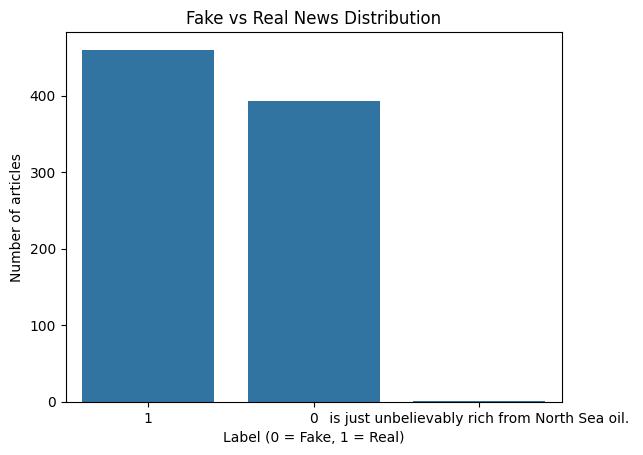

In [9]:
sns.countplot(data=df, x="label")

plt.title("Fake vs Real News Distribution")
plt.xlabel("Label (0 = Fake, 1 = Real)")
plt.ylabel("Number of articles")
plt.show()

In [10]:
print("Missing titles:", df["title"].isnull().sum())
print("Missing article texts:", df["text"].isnull().sum())
print("Missing labels:", df["label"].isnull().sum())

Missing titles: 14
Missing article texts: 13
Missing labels: 15


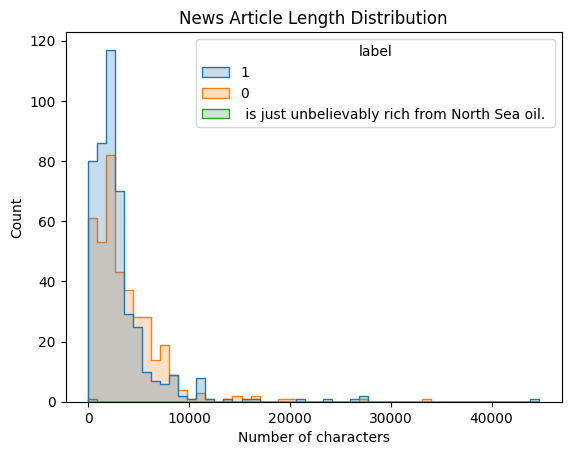

In [11]:
df["article_length"] = df["text"].fillna("").astype(str).str.len()

sns.histplot(
    data=df,
    x="article_length",
    hue="label",
    bins=50,
    element="step"
)

plt.title("News Article Length Distribution")
plt.xlabel("Number of characters")
plt.show()

In [12]:
# Remove unnecessary index columns
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

# Remove records without labels
df = df.dropna(subset=["label"]).copy()

# Convert labels to numeric values
df["label"] = pd.to_numeric(df["label"], errors="coerce")
df = df.dropna(subset=["label"]).copy()

# Keep only binary labels
df = df[df["label"].isin([0, 1])].copy()
df["label"] = df["label"].astype(int)

# Handle missing title and article text
df["title"] = df["title"].fillna("").astype(str)

df["text"] = df["text"].fillna("").astype(str)

# Remove exact duplicate records
df = df.drop_duplicates(subset=["title", "text", "label"])

print("Cleaned dataset shape:", df.shape)
print(df["label"].value_counts())

Cleaned dataset shape: (853, 4)
label
1    460
0    393
Name: count, dtype: int64


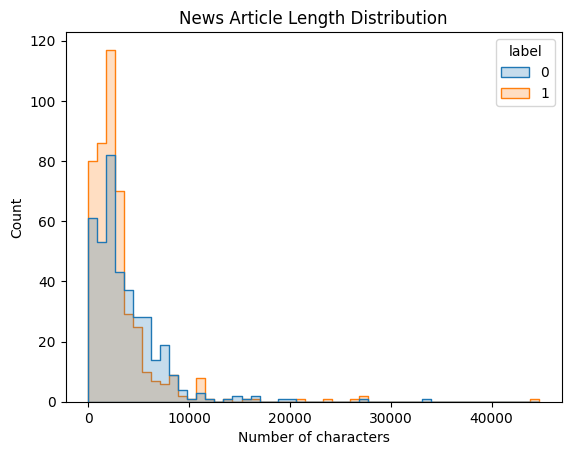

In [13]:
df["article_length"] = df["text"].fillna("").astype(str).str.len()

sns.histplot(
    data=df,
    x="article_length",
    hue="label",
    bins=50,
    element="step"
)

plt.title("News Article Length Distribution")
plt.xlabel("Number of characters")
plt.show()

In [14]:
def clean_text(text):
    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Convert to lowercase
    text = text.lower()

    # Replace punctuation and special characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Replace repeated whitespace with one space
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [15]:
sample = """
BREAKING NEWS!!! Visit https://example.com
The Government &amp; officials announced a policy.
"""

print("Original text:")
print(sample)

print("\nCleaned text:")
print(clean_text(sample))

Original text:

BREAKING NEWS!!! Visit https://example.com
The Government &amp; officials announced a policy.


Cleaned text:
breaking news visit the government officials announced a policy


In [16]:
df["combined_text"] = (
    df["title"] + " " + df["text"]
).apply(clean_text)

# Remove empty documents
df = df[df["combined_text"].str.len() > 0].copy()

print(df[["title", "label", "combined_text"]].head())
print("\nFinal shape:", df.shape)

                                               title  label  \
0  LAW ENFORCEMENT ON HIGH ALERT Following Threat...      1   
1                                                         1   
2  UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...      1   
3  Bobby Jindal, raised Hindu, uses story of Chri...      0   
4  SATAN 2: Russia unvelis an image of its terrif...      1   

                                       combined_text  
0  law enforcement on high alert following threat...  
1      did they post their votes for hillary already  
2  unbelievable obama s attorney general says mos...  
3  bobby jindal raised hindu uses story of christ...  
4  satan 2 russia unvelis an image of its terrify...  

Final shape: (851, 5)


In [17]:
from collections import Counter

def get_top_words(texts, top_n=20):
    words = []

    for text in texts:
        tokens = re.findall(r"\b[a-z]{3,}\b", text)
        words.extend(tokens)

    return Counter(words).most_common(top_n)


fake_texts = df.loc[df["label"] == 0, "combined_text"]
real_texts = df.loc[df["label"] == 1, "combined_text"]

fake_words = get_top_words(fake_texts)
real_words = get_top_words(real_texts)

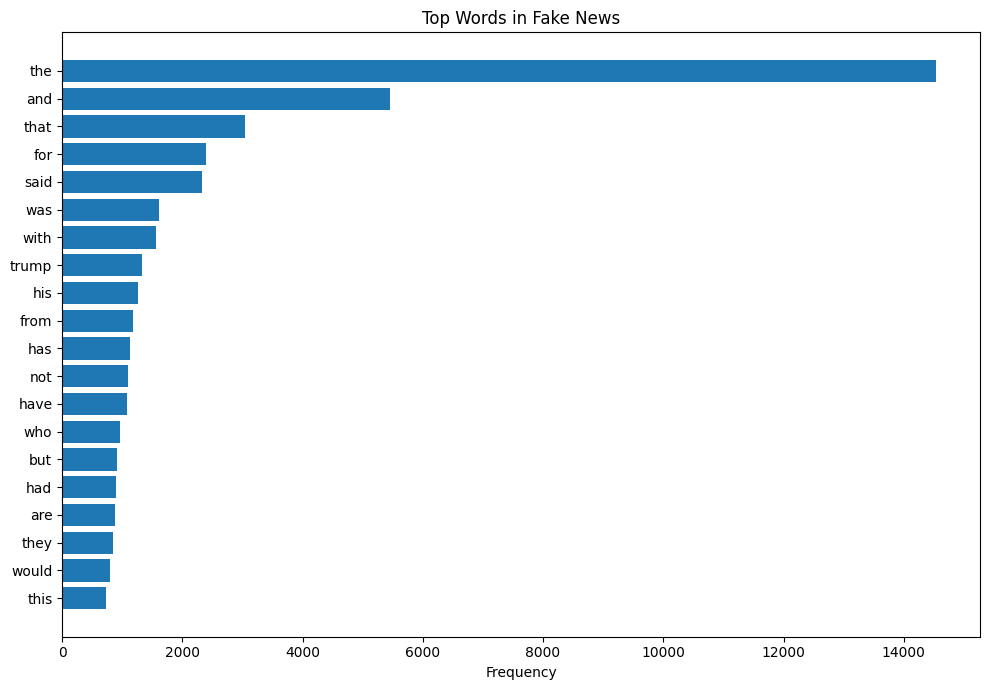

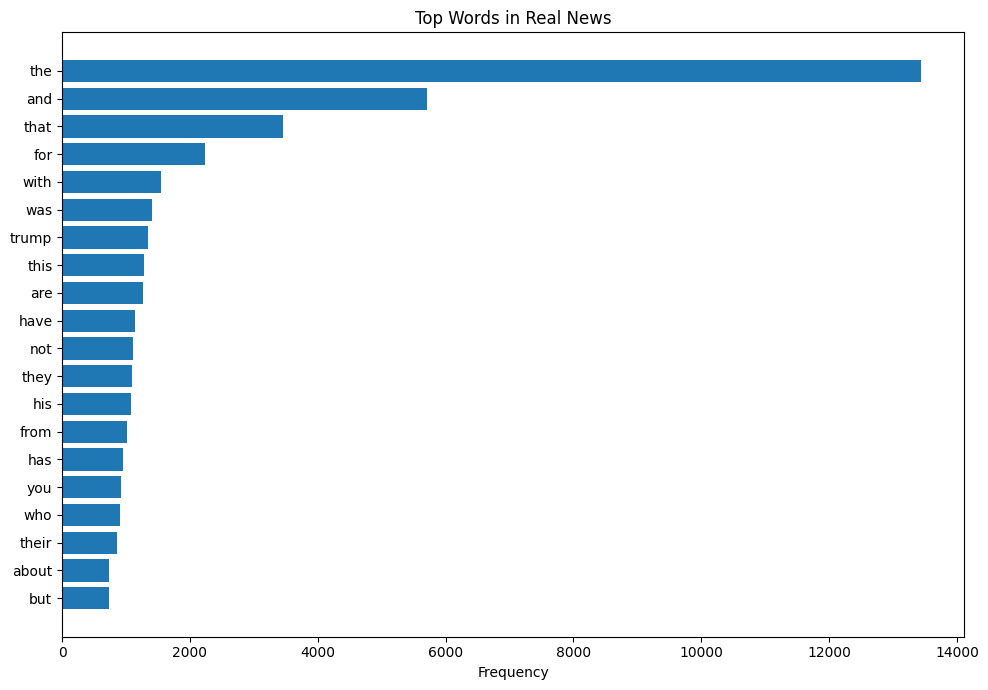

In [18]:
def plot_top_words(word_counts, title):
    words = [item[0] for item in word_counts][::-1]
    counts = [item[1] for item in word_counts][::-1]

    plt.figure(figsize=(10, 7))
    plt.barh(words, counts)
    plt.title(title)
    plt.xlabel("Frequency")
    plt.tight_layout()
    plt.show()


plot_top_words(fake_words, "Top Words in Fake News")
plot_top_words(real_words, "Top Words in Real News")

In [19]:
from sklearn.model_selection import train_test_split

X = df["combined_text"]
y = df["label"]

# First: reserve 15% for final testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Then: reserve 15% of the complete dataset for validation
# 0.17647 of the remaining 85% is approximately 15% overall
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.17647,
    random_state=42,
    stratify=y_train_val
)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Test examples:", len(X_test))

Training examples: 595
Validation examples: 128
Test examples: 128


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(
        random_state=42
    )
}

trained_models = {}
results = []

for name, classifier in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=30000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

    # Fit the entire pipeline on training data
    pipeline.fit(X_train, y_train)

    # Evaluate on validation data only
    predictions = pipeline.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)
    precision = precision_score(
        y_val, predictions, zero_division=0
    )
    recall = recall_score(
        y_val, predictions, zero_division=0
    )
    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")


Training Logistic Regression...
Accuracy:  0.9141
Precision: 0.9143
Recall:    0.9275
F1-score:  0.9209

Training Naive Bayes...
Accuracy:  0.8750
Precision: 0.8533
Recall:    0.9275
F1-score:  0.8889

Training Linear SVM...
Accuracy:  0.9219
Precision: 0.9538
Recall:    0.8986
F1-score:  0.9254


In [22]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

print(results_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1-score
         Linear SVM  0.921875   0.953846 0.898551  0.925373
Logistic Regression  0.914062   0.914286 0.927536  0.920863
        Naive Bayes  0.875000   0.853333 0.927536  0.888889


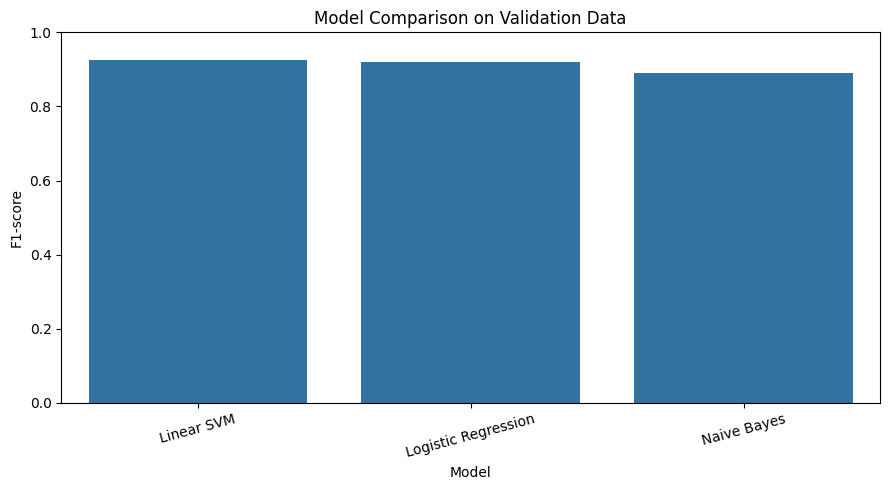

In [23]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1-score"
)

plt.title("Model Comparison on Validation Data")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [24]:
best_name = results_df.loc[0, "Model"]
best_model = trained_models[best_name]

print("Best model:", best_name)
print("Selected using validation F1-score.")

Best model: Linear SVM
Selected using validation F1-score.


In [25]:
from sklearn.base import clone

# Combine training and validation data
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

# Create a fresh copy of the selected pipeline
final_model = clone(best_model)

# Fit using training + validation data
final_model.fit(X_train_final, y_train_final)

# Evaluate once on the reserved test set
test_predictions = final_model.predict(X_test)

print("Selected model:", best_name)

print("\nFinal test accuracy:")
print(accuracy_score(y_test, test_predictions))

print("\nFinal classification report:")
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["Fake News", "Real News"],
        zero_division=0
    )
)

Selected model: Linear SVM

Final test accuracy:
0.9609375

Final classification report:
              precision    recall  f1-score   support

   Fake News       0.97      0.95      0.96        59
   Real News       0.96      0.97      0.96        69

    accuracy                           0.96       128
   macro avg       0.96      0.96      0.96       128
weighted avg       0.96      0.96      0.96       128



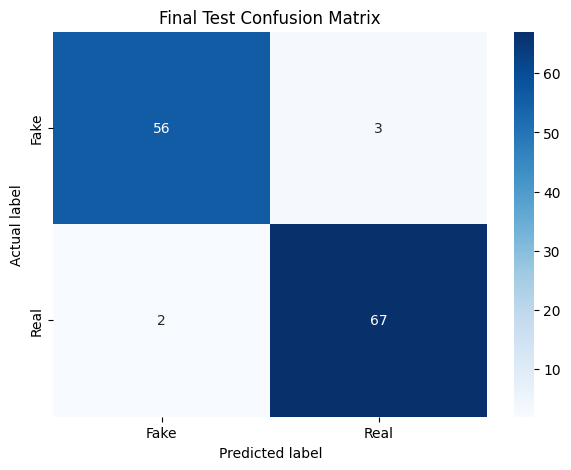

In [26]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Final Test Confusion Matrix")
plt.show()

Test ROC-AUC: 0.9882


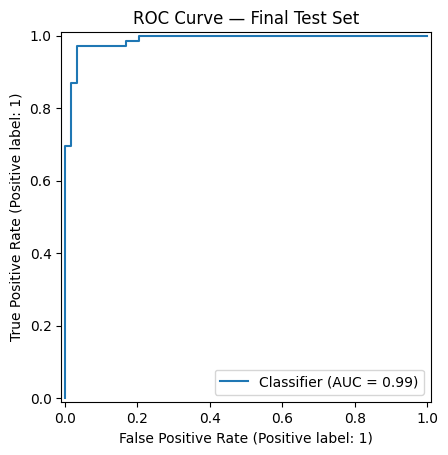

In [27]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

if hasattr(final_model, "predict_proba"):
    test_scores = final_model.predict_proba(X_test)[:, 1]
else:
    test_scores = final_model.decision_function(X_test)

auc = roc_auc_score(y_test, test_scores)

print("Test ROC-AUC:", round(auc, 4))

RocCurveDisplay.from_predictions(y_test, test_scores)
plt.title("ROC Curve — Final Test Set")
plt.show()

In [28]:
def predict_news(title, article):
    # Use exactly the same preprocessing as training
    combined_text = clean_text(title + " " + article)

    if not combined_text:
        print("Please enter a headline or article.")
        return

    prediction = final_model.predict([combined_text])[0]

    if prediction == 0:
        print("Model prediction: FAKE NEWS")
    else:
        print("Model prediction: REAL NEWS")

    # Display a probability only if supported by the classifier
    if hasattr(final_model, "predict_proba"):
        probabilities = final_model.predict_proba(
            [combined_text]
        )[0]

        predicted_index = list(final_model.classes_).index(
            prediction
        )

        print(
            "Predicted-class probability:",
            f"{probabilities[predicted_index]:.2%}"
        )
    else:
        print(
            "This classifier does not directly provide "
            "calibrated class probabilities."
        )

    print("\nRemember: a model prediction is not a fact-check.")


title = input("Enter a news headline: ")
article = input("Enter the news article: ")

predict_news(title, article)

Enter a news headline: died of accident
Enter the news article: a people fell from roof and died
Model prediction: REAL NEWS
This classifier does not directly provide calibrated class probabilities.

Remember: a model prediction is not a fact-check.


In [29]:
import joblib

os.makedirs("/content/models", exist_ok=True)

joblib.dump(
    final_model,
    "/content/models/fake_news_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [30]:
from google.colab import files

files.download("/content/models/fake_news_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>